# Step 16 — 2D Geostrophic Adjustment

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step16_geostrophic_adjustment.ipynb)

*The steps beyond Navier–Stokes, moved from somax's tutorial series.*

When a rotating fluid starts out of balance, it adjusts toward geostrophic equilibrium by radiating gravity waves. The final balanced state has the pressure-gradient force matching the Coriolis force, $f_0 v = g \partial h / \partial x$.

**What you'll learn:**

1. How to run 2D linear shallow water on a rotating $f$-plane
2. How a height step adjusts toward geostrophic balance
3. What the Rossby deformation radius $L_d = \sqrt{g H_0} / f_0$ sets

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

The linear rotating shallow-water equations for the height perturbation $h$ and the velocity $(u, v)$:

$$
\frac{\partial h}{\partial t} + H_0 \left(\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y}\right) = 0
$$

$$
\frac{\partial u}{\partial t} - f_0 v = -g \frac{\partial h}{\partial x}
$$

$$
\frac{\partial v}{\partial t} + f_0 u = -g \frac{\partial h}{\partial y}
$$

A steady solution has the velocity set by the height gradient, which for a height uniform in $y$ is the geostrophic jet $v = (g / f_0) \partial h / \partial x$.

### Symbols

The page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y)$ | spatial coordinates (m) | $\mathbb{R}^2$ |
| $t$ | time (s) | $\mathbb{R}$ |
| $h(x, y, t)$ | height perturbation (m) | $\mathbb{R}$ |
| $u(x, y, t)$, $v(x, y, t)$ | velocity components (m/s) | $\mathbb{R}$ |
| $v_g(x)$ | geostrophic velocity from the height gradient (m/s) | $\mathbb{R}$ |
| $g$, $H_0$, $f_0$ | gravity (m/s²), mean depth (m) and Coriolis parameter (1/s) | $\mathbb{R}_{>0}$ |
| $L_d$ | Rossby deformation radius (m) | $\mathbb{R}_{>0}$ |
| $\eta_0$ | half the initial height step (m) | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths (m) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$, $N_T$ | number of interior cells along $x$ and $y$, and of saved snapshots | count |
| $\Delta x$, $\Delta y$, $\Delta t$ | grid spacings (m) and time step (s) | $\mathbb{R}_{>0}$ |

In [2]:
import diffrax as dfx
import einx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 128 interior cells

num_cells = 128
domain_length = 1.0e6
gravity = 9.81
coriolis = 1.0e-4
mean_depth = 100.0

# today (sesmax_core)
model = sxt.LinearShallowWater2D.create(
    nx=num_cells,
    ny=num_cells,
    Lx=domain_length,
    Ly=domain_length,
    g=gravity,
    f0=coriolis,
    H0=mean_depth,
    bc="periodic",
)

# c = √(g H₀)
phase_speed = jnp.sqrt(gravity * mean_depth)  # → ()
# L_d = c / f₀
deformation_radius = phase_speed / coriolis  # → ()
print(f"Rossby deformation radius: Ld = {float(deformation_radius) / 1e3:.0f} km")
print(f"Grid spacing: dx = {model.grid.dx / 1e3:.1f} km")

Rossby deformation radius: Ld = 313 km
Grid spacing: dx = 7.8 km


## 2. Initial condition

A smooth height step, a $\tanh$ profile across the centre of the domain, with no initial velocity, so the flow must develop through adjustment. Periodic boundaries add a matching jump at the domain's edge, so the domain really holds two fronts.

In [5]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

step_height = 0.5

# xᵢ = i Δx
x_position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(model.grid.Ny) * model.grid.dy  # → (N_Ωx,y + 2,)
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# h₀ = −η₀ tanh((x − L_x / 2) / (L_x / 20))
scaled_x = (x_grid - domain_length / 2.0) / (domain_length / 20.0)  # → G
initial_height = -step_height * jnp.tanh(scaled_x)  # → G
at_rest = jnp.zeros_like(initial_height)  # → G
# today (sesmax_core)
initial_state = sxt.LinearSW2DState(h=initial_height, u=at_rest, v=at_rest)

## 3. Forward simulation

We integrate for about 55 hours, several inertial periods, and save 150 snapshots.

In [6]:
# Shapes: N_T = 150 saved snapshots; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

end_time = 2.0e5
# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 150)  # → (N_T,)
# Δt = 0.4 Δx / c
time_step = 0.4 * model.grid.dx / phase_speed  # → ()

# today (sesmax_core, diffrax)
solution = model.integrate(  # h, u, v → N_T × G each
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)
print(f"All finite: {bool(jnp.all(jnp.isfinite(solution.ys.h)))}")

All finite: True


## 4. Visualise the adjustment

The height step slumps and the velocity spins up along it. The problem is uniform in $y$, so a Hovmöller diagram along $x$ shows the gravity waves leaving the fronts. They cannot leave the domain: it is periodic and the model has no viscosity or drag, so they keep crossing it, and any one snapshot is dominated by them, as the small $v$ in the middle panel shows.

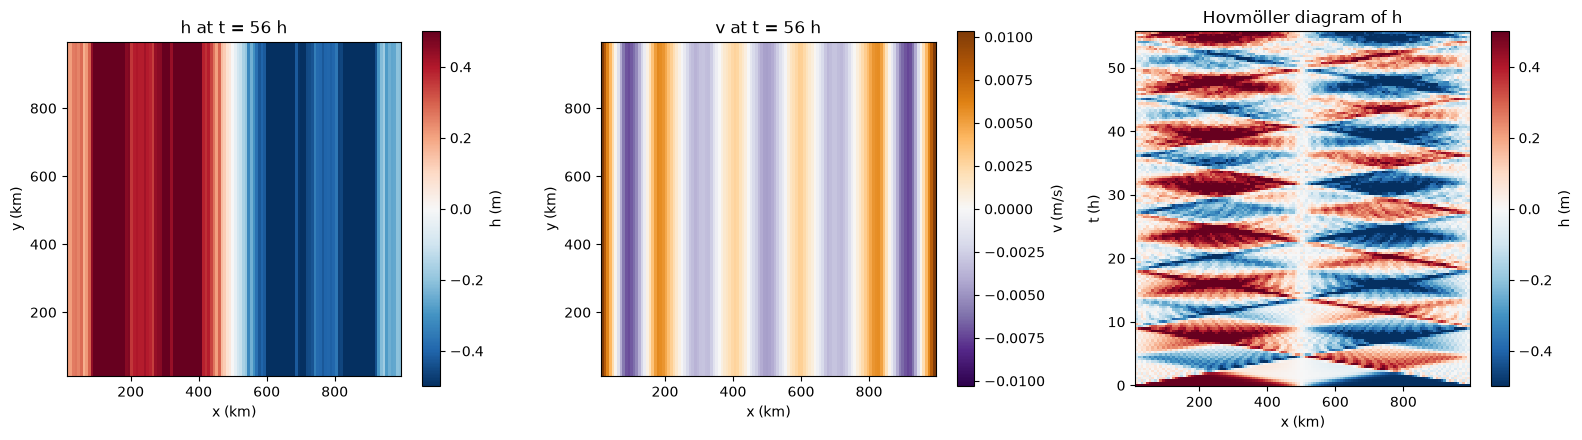

In [7]:
# Shapes: N_Ωx,x = 128 columns; N_Ωx,y = 128 rows; N_T = 150 saved snapshots

inner = slice(2, -2)
interior = (inner, inner)
x_km = x_position[inner] / 1e3
y_km = y_position[inner] / 1e3
time_hours = save_times / 3600.0  # → (N_T,)
middle_row = num_cells // 2
final_h = solution.ys.h[-1]  # → G
final_v = solution.ys.v[-1]  # → G

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

mesh = axes[0].pcolormesh(
    x_km,
    y_km,
    final_h[interior],
    cmap="RdBu_r",
    vmin=-step_height,
    vmax=step_height,
    shading="auto",
)
axes[0].set_title(f"h at t = {float(time_hours[-1]):.0f} h")
axes[0].set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")
axes[0].set_aspect("equal")
plt.colorbar(mesh, ax=axes[0], label="h (m)")

largest_v = float(jnp.max(jnp.abs(final_v[interior])))
mesh = axes[1].pcolormesh(
    x_km,
    y_km,
    final_v[interior],
    cmap="PuOr_r",
    vmin=-largest_v,
    vmax=largest_v,
    shading="auto",
)
axes[1].set_title(f"v at t = {float(time_hours[-1]):.0f} h")
axes[1].set_xlabel("x (km)")
axes[1].set_ylabel("y (km)")
axes[1].set_aspect("equal")
plt.colorbar(mesh, ax=axes[1], label="v (m/s)")

mesh = axes[2].pcolormesh(
    x_km,
    time_hours,
    solution.ys.h[:, middle_row, inner],
    cmap="RdBu_r",
    vmin=-step_height,
    vmax=step_height,
    shading="auto",
)
axes[2].set_title("Hovmöller diagram of h")
axes[2].set_xlabel("x (km)")
axes[2].set_ylabel("t (h)")
plt.colorbar(mesh, ax=axes[2], label="h (m)")

plt.tight_layout()
plt.show()

## 5. Balance check

If the flow has reached geostrophic balance, $v$ along a row should match $v_g = (g / f_0) \partial h / \partial x$. The waves average out over an inertial period, so we compare the time means over the last one. The jump at the domain's edge stays one cell wide, so we leave the outermost 5 columns on each side out of the comparison and the plot.

RMS of the time-mean v: 0.0474 m/s
RMS of v - v_g:         0.0321 m/s
Correlation of v and v_g: 0.944


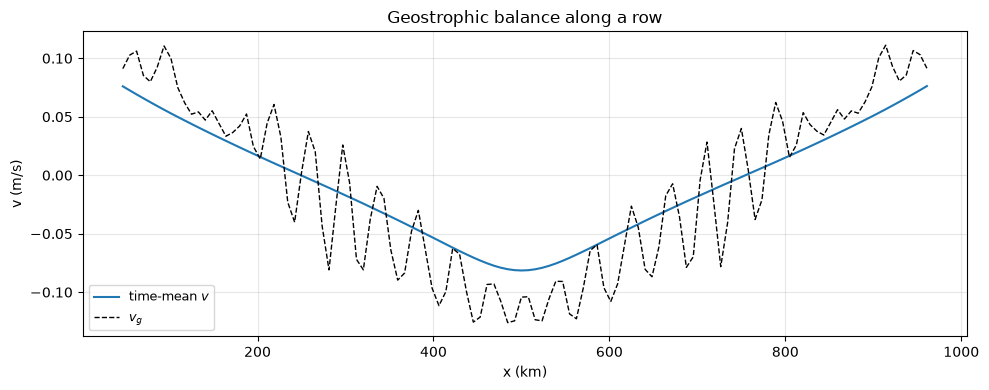

In [8]:
# Shapes: N_Ωx,x = 128 columns; N_T = 150 saved snapshots

# T_f = 2π / f₀
inertial_period = 2.0 * jnp.pi / coriolis  # → ()
last_period = save_times >= end_time - inertial_period  # → (N_T,)

# h̄(x), v̄(x) over the last inertial period, along one row
row_height = solution.ys.h[last_period, middle_row, :]  # → (N_last, N_Ωx,x + 2)
row_velocity = solution.ys.v[last_period, middle_row, :]  # → (N_last, N_Ωx,x + 2)
mean_height = einx.mean("[time] x -> x", row_height)  # → (N_Ωx,x + 2,)
mean_velocity = einx.mean("[time] x -> x", row_velocity)  # → (N_Ωx,x + 2,)

# ∂h̄/∂x ≈ (h̄ᵢ₊₁ − h̄ᵢ₋₁) / (2 Δx), on the interior columns
height_gradient = (mean_height[2:] - mean_height[:-2]) / (2.0 * model.grid.dx)
# v_g = (g / f₀) ∂h̄/∂x
geostrophic_velocity = gravity / coriolis * height_gradient  # → (N_Ωx,x,)
interior_velocity = mean_velocity[1:-1]  # → (N_Ωx,x,)

# Away from the one-cell jump at the domain's edge
away = slice(5, -5)
compared_velocity = interior_velocity[away]  # → (N_Ωx,x − 10,)
compared_balance = geostrophic_velocity[away]  # → (N_Ωx,x − 10,)
# ‖v̄ − v_g‖_RMS
residual = compared_velocity - compared_balance  # → (N_Ωx,x − 10,)
rms_residual = jnp.sqrt(jnp.mean(residual**2))  # → ()
rms_velocity = jnp.sqrt(jnp.mean(compared_velocity**2))  # → ()
# r = ∑ v̄ v_g / √(∑ v̄² ∑ v_g²)
inner_product = einx.dot("[x], [x] ->", compared_velocity, compared_balance)  # → ()
norm_velocity = einx.dot("[x], [x] ->", compared_velocity, compared_velocity)  # → ()
norm_balance = einx.dot("[x], [x] ->", compared_balance, compared_balance)  # → ()
correlation = inner_product / jnp.sqrt(norm_velocity * norm_balance)  # → ()
print(f"RMS of the time-mean v: {float(rms_velocity):.4f} m/s")
print(f"RMS of v - v_g:         {float(rms_residual):.4f} m/s")
print(f"Correlation of v and v_g: {float(correlation):.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
column_km = x_position[1:-1] / 1e3  # → (N_Ωx,x,)
ax.plot(column_km[away], compared_velocity, lw=1.5, label="time-mean $v$")
ax.plot(column_km[away], compared_balance, "k--", lw=1.0, label="$v_g$")
ax.set_xlabel("x (km)")
ax.set_ylabel("v (m/s)")
ax.set_title("Geostrophic balance along a row")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The time-mean $v$ follows the smooth part of $v_g$, with the correlation printed above. The ripples in $v_g$ are height waves that one inertial period does not fully average out, and they account for most of the printed residual.

## Summary

| Concept | sesmax API |
| --- | --- |
| Create the model | `LinearShallowWater2D.create(nx, ny, Lx, Ly, g, f0, H0, bc="periodic")` |
| Initial state | `LinearSW2DState(h=..., u=..., v=...)` |
| Forward simulation | `model.integrate(state0, t0, t1, dt, saveat=...)` |

- An initial height step adjusts toward geostrophic balance on the rotating $f$-plane.
- Gravity waves carry the unbalanced part away from the fronts, leaving a jet along each one. On this periodic domain the waves stay, so the balance shows in the time mean, not in a snapshot.
- In theory the width over which the height adjusts scales with the Rossby deformation radius $L_d$. Here $L_d$ is about a third of the domain, so the two fronts' jets fill it.